In [20]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_blobs, make_classification
from sklearn.model_selection import train_test_split
from helper_functions import plot_decision_boundary
from sklearn.metrics import ConfusionMatrixDisplay
from torchmetrics.classification import (
    MulticlassROC,
    MulticlassAUROC,
    MulticlassPrecisionRecallCurve,
    MulticlassConfusionMatrix,
)

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torchmetrics

In [2]:
%load_ext jupyter_black

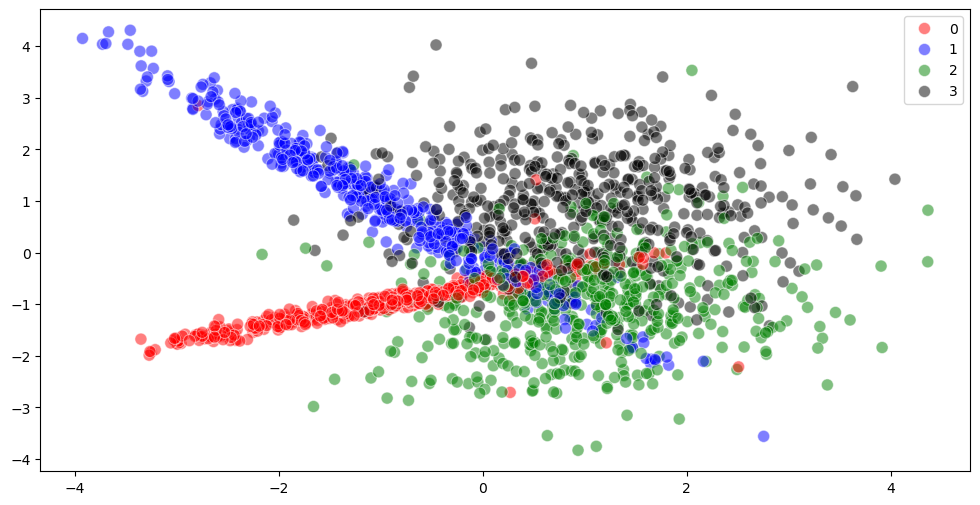

In [3]:
X, y = make_classification(
    n_samples=2000,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    n_classes=4,
    class_sep=1.0,
)
plt.figure(figsize=(12, 6))
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=y,
    palette=["red", "blue", "green", "black"],
    alpha=0.5,
    s=75,
)
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2)
X_train = torch.FloatTensor(X_train)
y_train = torch.LongTensor(y_train)
X_test = torch.FloatTensor(X_test)
y_test = torch.LongTensor(y_test)

In [5]:
ds = TensorDataset(X_train, y_train)
ds

In [6]:
ds[0]

(tensor([ 1.8790, -1.7546]), tensor(2))

In [7]:
len(ds)

1600

In [8]:
loader = DataLoader(dataset=ds, batch_size=32, shuffle=True)

In [9]:
class Model(nn.Module):
    def __init__(self, features, classes):
        super().__init__()
        self.sequence = nn.Sequential(
            nn.Linear(features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, classes),
        )

    def forward(self, X):
        return self.sequence(X)

    def train_model(
        self, optimizer, loader, criteration=nn.CrossEntropyLoss(), epochs=1000
    ):
        train_loss = []
        for epoch in range(epochs):
            self.train()
            mini_batch_loss = 0
            for X, y in loader:
                y_hat = self(X)
                loss = criteration(y_hat, y)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                mini_batch_loss += loss.item()
            train_loss.append(mini_batch_loss / len(loader))
        plt.figure()
        plt.title("Mini Batch Trainig")
        plt.xlabel("Epochs")
        plt.ylabel("Average Loss")
        plt.plot(train_loss)
        plt.show()

In [10]:
model = Model(X_train.shape[1], len(torch.unique(y_train)))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

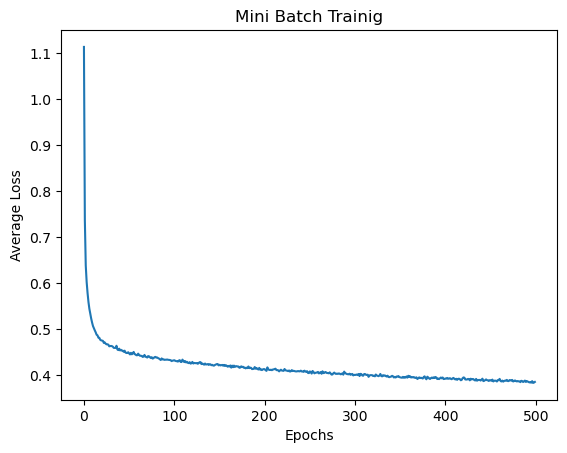

In [11]:
model.train_model(optimizer, loader, epochs=500)

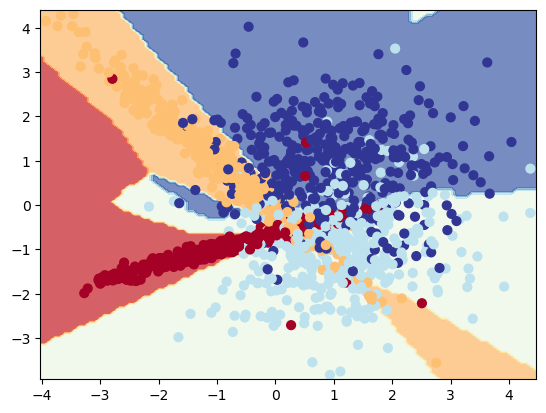

In [12]:
plot_decision_boundary(model, X_train, y_train)

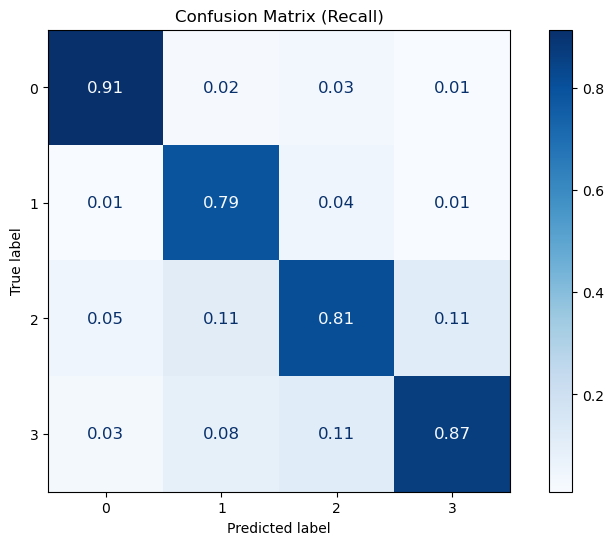

In [13]:
model.eval()
with torch.inference_mode():
    pred = model(X_test).argmax(dim=1)
plt.figure(figsize=(10, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(),
    pred.numpy(),
    normalize="pred",
    cmap="Blues",
    values_format=".2f",
    text_kw={"size": 12},
    ax=plt.gca(),
)
plt.title("Confusion Matrix (Recall)")
plt.show()

In [24]:
metric = MulticlassConfusionMatrix(num_classes=4, normalize="pred")

model.eval()
with torch.inference_mode():
    logits = model(X_test)

cm = metric(logits, y_test)
cm

tensor([[0.9135, 0.0169, 0.0337, 0.0112],
        [0.0096, 0.7881, 0.0449, 0.0112],
        [0.0481, 0.1102, 0.8090, 0.1124],
        [0.0288, 0.0847, 0.1124, 0.8652]])

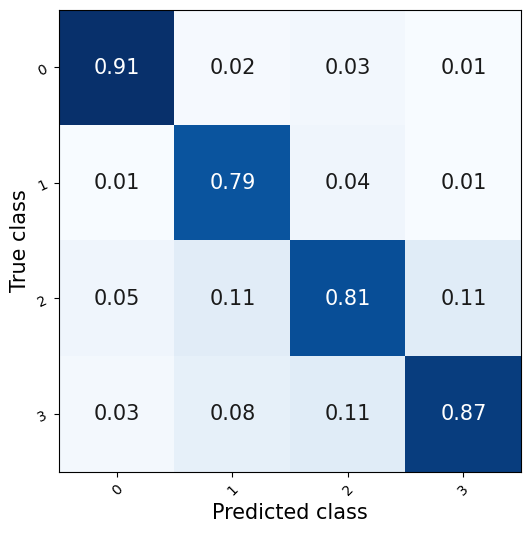

In [25]:
plt.figure(figsize=(10, 6))
metric.plot(cmap="Blues", ax=plt.gca())
plt.show()

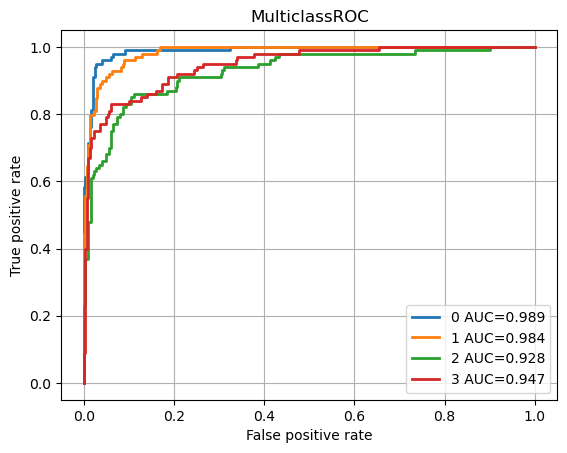

In [17]:
roc = MulticlassROC(num_classes=4)
with torch.inference_mode():
    logits = model(X_test)
probs = torch.softmax(logits, dim=1)

roc.update(probs, y_test)
fig, ax = roc.plot(score=True)
plt.show()

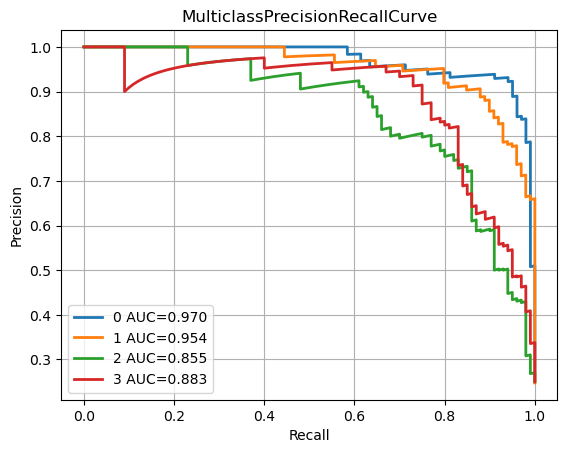

In [23]:
with torch.inference_mode():
    probs = torch.softmax(model(X_test), dim=1)

pr = MulticlassPrecisionRecallCurve(num_classes=4)
pr.update(probs, y_test)
fig, ax = pr.plot(score=True)
plt.show()